# 💻 Laptop Fair-Price & Value Engine
**Machine Learning · Final Project**

## 1 · Problem framing
- **Who has the problem?** An IT department / PC-lab manager (or a buyer) who has to decide whether a machine is worth its price, which machines to keep, upgrade or retire, and what a new purchase should cost.
- **Decision supported:** *"Given a machine's specs, what is its fair price, is the quoted price a good deal, and which hardware tier does it belong to?"*
- **Target:** `Price` (regression). Prices are right-skewed, so the model is trained on `log(price)`.
- **Metrics:** **MAE** (average error in price units, easy to explain), **RMSE** (penalises big mistakes) and **R²** (share of variance explained). MAE is the headline metric because a manager reads it as *"the model is off by about X on a typical laptop"*.
- **Second task (unsupervised):** K-Means + PCA to group machines into hardware tiers.
- **Bridge to a rule-based system:** we compare the learned model against a hand-written hardware score, like the rule-based ranking in a PC-management tool.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from features import parse_raw, rule_based_score, FEATURES, NUM_COLS, CAT_COLS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
import os; os.makedirs("models", exist_ok=True); os.makedirs("assets", exist_ok=True)
RESULTS = {}   # every number reported in the README is saved from here

## 2 · Data understanding
**Source:** a public laptop-price table (1,303 laptops) hosted in the GitHub repo `AAdewunmi/laptop_prices_prediction_project` (`sample_data/laptop_data.csv`); it appears to be the widely used Kaggle *Laptop Price* dataset. The `Price` column is in the file's own currency units (the values look like rupee-converted list prices), so we simply call them **price units** and never convert.

In [2]:
raw = pd.read_csv("data/laptop_data.csv", index_col=0)
print("Shape:", raw.shape)
display(raw.head())
print(raw.dtypes)
print("\nMissing values per column:\n", raw.isna().sum())
print("\nExact duplicate rows:", raw.duplicated().sum())

Shape: (1303, 11)


,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


Company                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                     str
Memory                  str
Gpu                     str
OpSys                   str
Weight                  str
Price               float64
dtype: object

Missing values per column:
 Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

Exact duplicate rows: 29


**Column dictionary (raw):** `Company` (brand), `TypeName` (laptop category), `Inches` (screen size), `ScreenResolution` (text: resolution + IPS/Touchscreen flags), `Cpu` (text: brand, family, GHz), `Ram` (e.g. `8GB`), `Memory` (storage text, may combine drives like `256GB SSD + 1TB HDD`), `Gpu`, `OpSys`, `Weight` (e.g. `1.37kg`), `Price` (**target**).

There are no missing values, but almost every column is a *text string* that hides numbers. Exact duplicates are removed **before** splitting, otherwise the same laptop could land in both train and test and inflate the scores.

In [3]:
n_before = len(raw)
raw = raw.drop_duplicates().reset_index(drop=True)
RESULTS["rows_raw"] = int(n_before); RESULTS["rows_after_dedup"] = int(len(raw))
print(f"Removed {n_before-len(raw)} duplicate rows -> {len(raw)} laptops")

# Row-wise text parsing (no statistics are learned here, so it is safe before the split)
X_all = parse_raw(raw)
y_all = raw["Price"].astype(float)
display(X_all.head())
print(X_all.isna().sum()[X_all.isna().sum() > 0])
print("Target skew:", round(y_all.skew(), 2), "| log-target skew:", round(np.log1p(y_all).skew(), 2))

Removed 29 duplicate rows -> 1274 laptops


,Company,TypeName,Cpu_brand,Gpu_brand,OS_group,Inches,Ram_GB,Weight_kg,Cpu_GHz,SSD_GB,HDD_GB,Hybrid_GB,Flash_GB,PPI,Touchscreen,IPS,Dedicated_GPU
0,Apple,Ultrabook,Intel Core i5,Intel,macOS,13.3,8.0,1.37,2.3,128.0,0.0,0.0,0.0,226.983005,0,1,0
1,Apple,Ultrabook,Intel Core i5,Intel,macOS,13.3,8.0,1.34,1.8,0.0,0.0,0.0,128.0,127.677940,0,0,0
2,HP,Notebook,Intel Core i5,Intel,Other / No OS,15.6,8.0,1.86,2.5,256.0,0.0,0.0,0.0,141.211998,0,0,0
3,Apple,Ultrabook,Intel Core i7,AMD,macOS,15.4,16.0,1.83,2.7,512.0,0.0,0.0,0.0,220.534624,0,1,1
4,Apple,Ultrabook,Intel Core i5,Intel,macOS,13.3,8.0,1.37,3.1,256.0,0.0,0.0,0.0,226.983005,0,1,0


Series([], dtype: int64)
Target skew: 1.51 | log-target skew: -0.18


## 3 · Exploratory data analysis

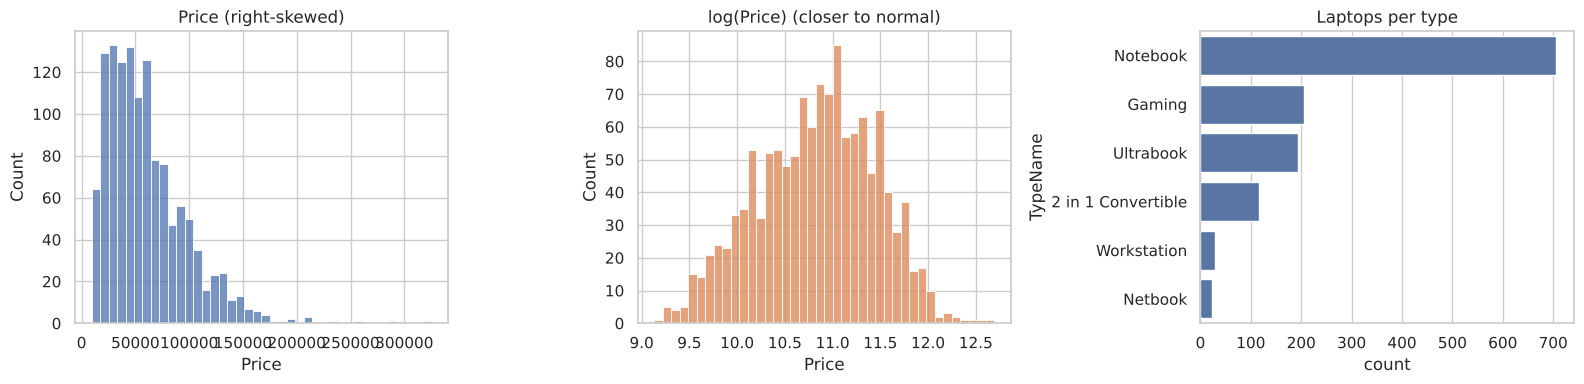

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y_all, bins=40, ax=ax[0]); ax[0].set_title("Price (right-skewed)")
sns.histplot(np.log1p(y_all), bins=40, ax=ax[1], color="C1"); ax[1].set_title("log(Price) (closer to normal)")
sns.countplot(data=X_all, y="TypeName", order=X_all.TypeName.value_counts().index, ax=ax[2]); ax[2].set_title("Laptops per type")
plt.tight_layout(); plt.savefig("assets/eda_univariate.png", dpi=110); plt.show()

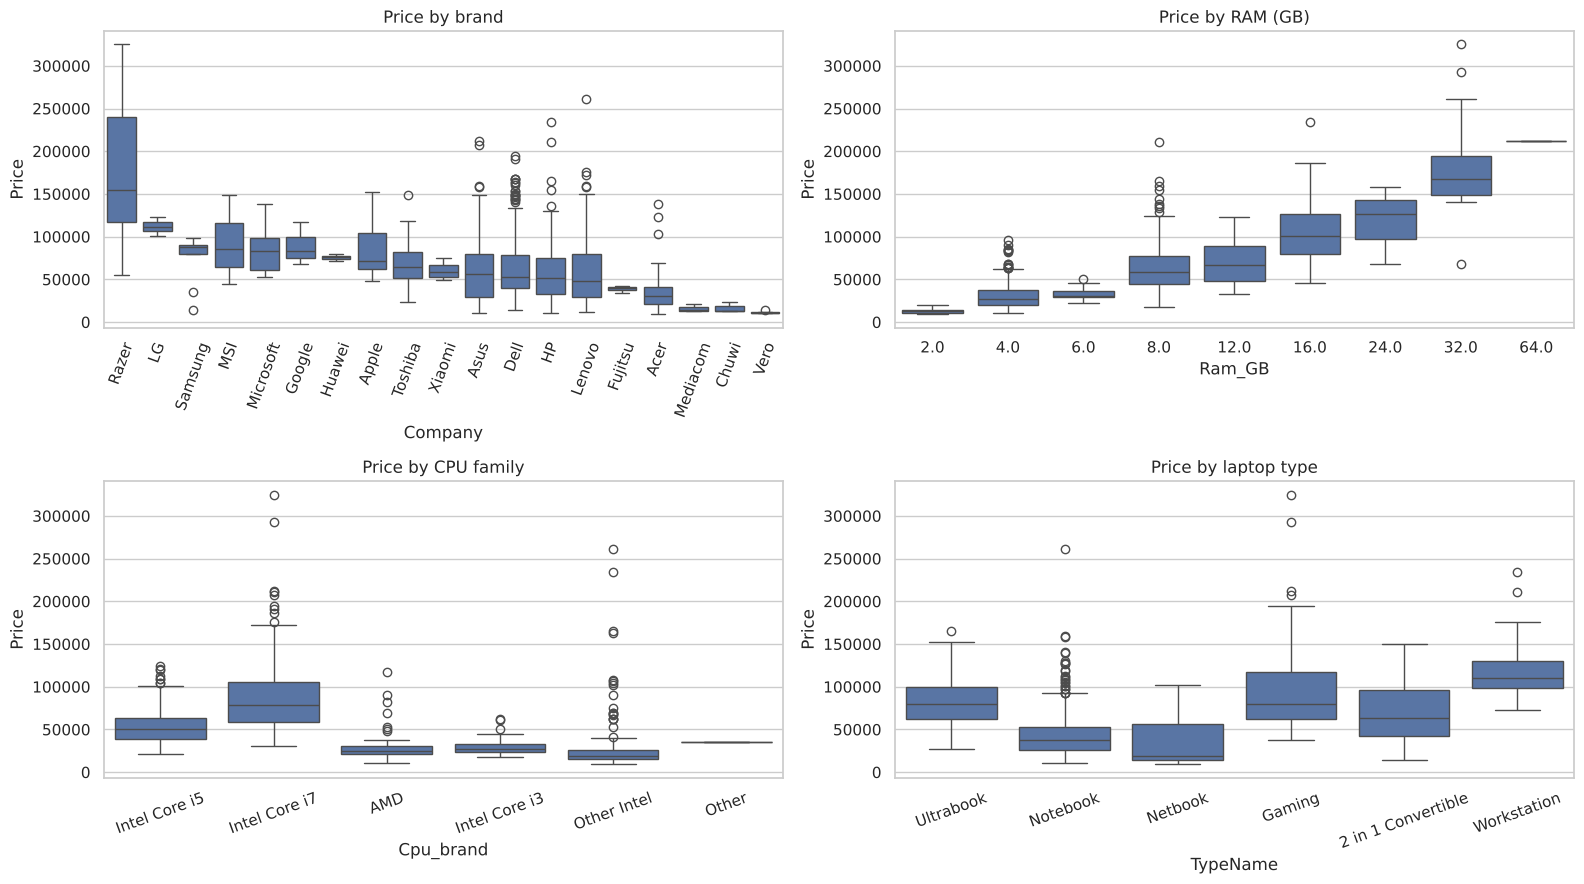

In [5]:
eda = X_all.assign(Price=y_all)
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
order = eda.groupby("Company").Price.median().sort_values(ascending=False).index
sns.boxplot(data=eda, x="Company", y="Price", order=order, ax=ax[0,0]); ax[0,0].tick_params(axis="x", rotation=70); ax[0,0].set_title("Price by brand")
sns.boxplot(data=eda, x="Ram_GB", y="Price", ax=ax[0,1]); ax[0,1].set_title("Price by RAM (GB)")
sns.boxplot(data=eda, x="Cpu_brand", y="Price", ax=ax[1,0]); ax[1,0].tick_params(axis="x", rotation=20); ax[1,0].set_title("Price by CPU family")
sns.boxplot(data=eda, x="TypeName", y="Price", ax=ax[1,1]); ax[1,1].tick_params(axis="x", rotation=20); ax[1,1].set_title("Price by laptop type")
plt.tight_layout(); plt.savefig("assets/eda_bivariate.png", dpi=110); plt.show()

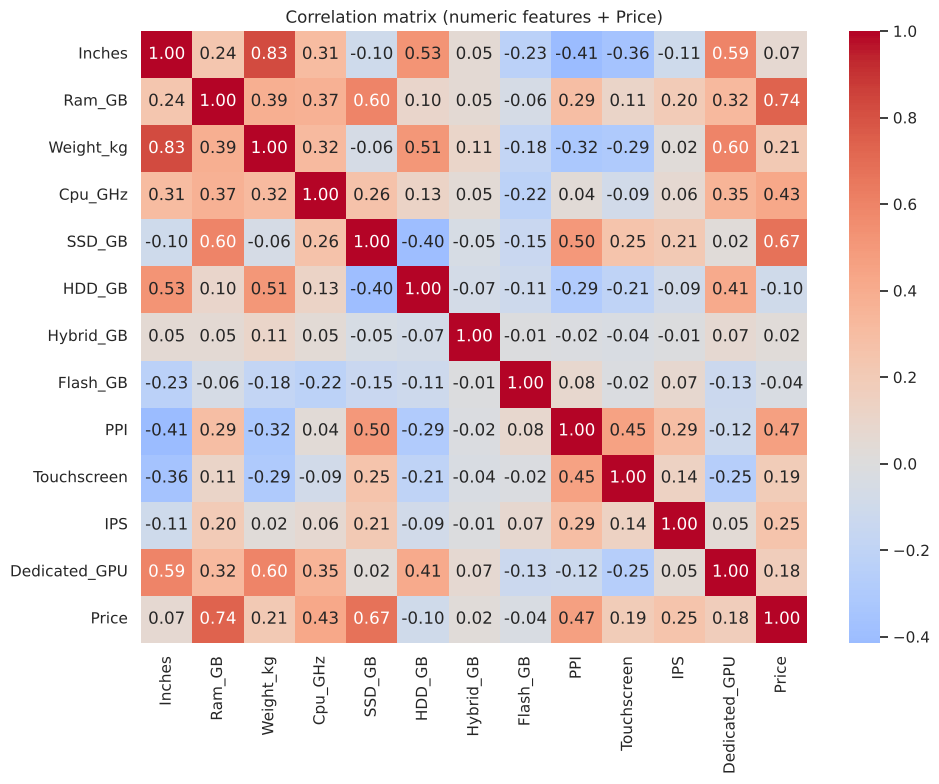

Ram_GB           0.74
SSD_GB           0.67
PPI              0.47
Cpu_GHz          0.43
IPS              0.25
Weight_kg        0.21
Touchscreen      0.19
Dedicated_GPU    0.18
Inches           0.07
Hybrid_GB        0.02
Flash_GB        -0.04
HDD_GB          -0.10
Name: Price, dtype: float64


In [6]:
corr = eda[NUM_COLS + ["Price"]].corr()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features + Price)"); plt.tight_layout()
plt.savefig("assets/eda_corr.png", dpi=110); plt.show()
top_corr = corr["Price"].drop("Price").sort_values(ascending=False)
print(top_corr.round(2))
RESULTS["top_corr"] = {k: round(float(v), 3) for k, v in top_corr.head(5).items()}

In [7]:
print("Median price by dedicated GPU:\n", eda.groupby("Dedicated_GPU").Price.median().round(0))
print("\nMedian price by storage type present:")
for c in ["SSD_GB", "HDD_GB"]:
    print(c, "> 0:", round(eda[eda[c] > 0].Price.median()), "| == 0:", round(eda[eda[c] == 0].Price.median()))
print("\nMedian price by brand (top 3 / bottom 3):")
med = eda.groupby("Company").Price.median().sort_values()
print(med.tail(3).round(0)); print(med.head(3).round(0))

Median price by dedicated GPU:
 Dedicated_GPU
0    49444.0
1    55837.0
Name: Price, dtype: float64

Median price by storage type present:
SSD_GB > 0: 67399 | == 0: 30316
HDD_GB > 0: 42944 | == 0: 59887

Median price by brand (top 3 / bottom 3):
Company
Samsung     87859.0
LG         111835.0
Razer      154459.0
Name: Price, dtype: float64
Company
Vero        11021.0
Chuwi       13261.0
Mediacom    14119.0
Name: Price, dtype: float64


### EDA insights / hypotheses
1. **Price is right-skewed**, so modelling `log(price)` should stabilise errors and avoid the model being dominated by a few very expensive machines.
2. **RAM, SSD size, PPI (screen sharpness) and CPU speed are the strongest numeric price signals** (see the correlation table above): price rises in clear steps with RAM and CPU family.
3. **Brand and laptop type shift price at equal specs** (e.g. gaming and workstation types, and premium brands, cost more): the categorical features will matter.
4. **Spec columns overlap** (RAM, SSD, PPI move together), which suggests linear models will do reasonably well but tree ensembles may capture the interactions better.
5. Several rare categories (some brands, ARM GPUs, Android/Chrome OS) have very few rows, so `handle_unknown="ignore"` in the encoder is needed to keep the app from crashing on rare input.

## 4 · Preprocessing & pipeline (split first, no leakage)
The **train/test split happens before anything is fitted**. Imputing, scaling and one-hot encoding live in a `ColumnTransformer` inside the `Pipeline`, so they are learned from training folds only (also inside cross-validation). The test set is touched **once**, at the very end.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
RESULTS["n_train"] = int(len(X_train)); RESULTS["n_test"] = int(len(X_test))

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_COLS),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT_COLS),
])

def make_model(estimator):
    # log-transform the target inside the model; predictions come back in price units
    pipe = Pipeline([("prep", preprocess), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def evaluate(model, X, y):
    p = model.predict(X)
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p)}

Train: (1019, 17) | Test: (255, 17)


## 5 · Modeling
A baseline (always predicts the mean) plus **three different algorithms**: Ridge regression (linear), Random Forest (bagged trees) and Gradient Boosting (boosted trees). First we compare them with 5-fold cross-validation on the **training data only**.

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "Baseline (mean)": make_model(DummyRegressor(strategy="mean")),
    "Ridge": make_model(Ridge(alpha=1.0)),
    "Random Forest": make_model(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_model(GradientBoostingRegressor(random_state=RANDOM_STATE)),
}
rows = []
for name, m in candidates.items():
    oof = cross_val_predict(m, X_train, y_train, cv=cv)
    rows.append({"Model": name, "CV MAE": mean_absolute_error(y_train, oof),
                 "CV RMSE": np.sqrt(mean_squared_error(y_train, oof)), "CV R2": r2_score(y_train, oof)})
cv_table = pd.DataFrame(rows).set_index("Model").round(3)
display(cv_table)
RESULTS["cv_untuned"] = cv_table.round(3).to_dict(orient="index")

,CV MAE,CV RMSE,CV R2
Model,,,
Baseline (mean),27817.630,37567.008,-0.077
Ridge,12785.096,20204.503,0.688
Random Forest,9919.522,15819.548,0.809
Gradient Boosting,10228.141,16003.289,0.805


## 6 · Tuning & validation
`RandomizedSearchCV` with 5-fold cross-validation on the training set, scoring negative MAE. Nothing from the test set is used.

In [10]:
searches = {
    "Ridge": (make_model(Ridge()), {"regressor__model__alpha": np.logspace(-2, 2, 30)}),
    "Random Forest": (make_model(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)), {
        "regressor__model__n_estimators": [200, 300, 500],
        "regressor__model__max_depth": [None, 10, 15, 25],
        "regressor__model__min_samples_leaf": [1, 2, 4],
        "regressor__model__max_features": [0.3, 0.5, 0.8, 1.0]}),
    "Gradient Boosting": (make_model(GradientBoostingRegressor(random_state=RANDOM_STATE)), {
        "regressor__model__n_estimators": [200, 300, 500],
        "regressor__model__learning_rate": [0.02, 0.05, 0.1],
        "regressor__model__max_depth": [2, 3, 4],
        "regressor__model__subsample": [0.7, 0.85, 1.0],
        "regressor__model__min_samples_leaf": [1, 3, 5]}),
}
tuned = {}
for name, (model, grid) in searches.items():
    rs = RandomizedSearchCV(model, grid, n_iter=20, cv=cv, scoring="neg_mean_absolute_error",
                            random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    rs.fit(X_train, y_train)
    tuned[name] = rs
    print(f"{name:18s} best CV MAE = {-rs.best_score_:,.0f}")
    print("   ", {k.split('__')[-1]: v for k, v in rs.best_params_.items()})
RESULTS["tuned_cv_mae"] = {k: round(float(-v.best_score_), 1) for k, v in tuned.items()}
RESULTS["best_params"] = {k: {kk.split('__')[-1]: (vv.item() if hasattr(vv, 'item') else vv) for kk, vv in v.best_params_.items()} for k, v in tuned.items()}

Ridge              best CV MAE = 12,674
    {'alpha': np.float64(0.01)}


Random Forest      best CV MAE = 9,852
    {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 15}


Gradient Boosting  best CV MAE = 9,287
    {'subsample': 0.7, 'n_estimators': 500, 'min_samples_leaf': 3, 'max_depth': 4, 'learning_rate': 0.05}


## 7 · Final evaluation on the untouched test set

In [11]:
final = {"Baseline (mean)": candidates["Baseline (mean)"].fit(X_train, y_train)}
final.update({k: v.best_estimator_ for k, v in tuned.items()})
test_table = pd.DataFrame({k: evaluate(m, X_test, y_test) for k, m in final.items()}).T
display(test_table.round(3))
RESULTS["test"] = test_table.round(3).to_dict(orient="index")

best_name = test_table.drop("Baseline (mean)")["MAE"].idxmin()
# Model selection used the CV score (not the test set); we report which wins on CV as well
cv_best = min(RESULTS["tuned_cv_mae"], key=RESULTS["tuned_cv_mae"].get)
print("Best on CV:", cv_best, "| Best on test:", best_name)
best_model = final[cv_best]          # choose by CV to keep the test set honest
RESULTS["best_model"] = cv_best

,MAE,RMSE,R2
Baseline (mean),28663.142,43464.487,-0.102
Ridge,14093.762,28207.059,0.536
Random Forest,11173.760,20641.291,0.751
Gradient Boosting,10996.413,19894.914,0.769


Best on CV: Gradient Boosting | Best on test: Gradient Boosting


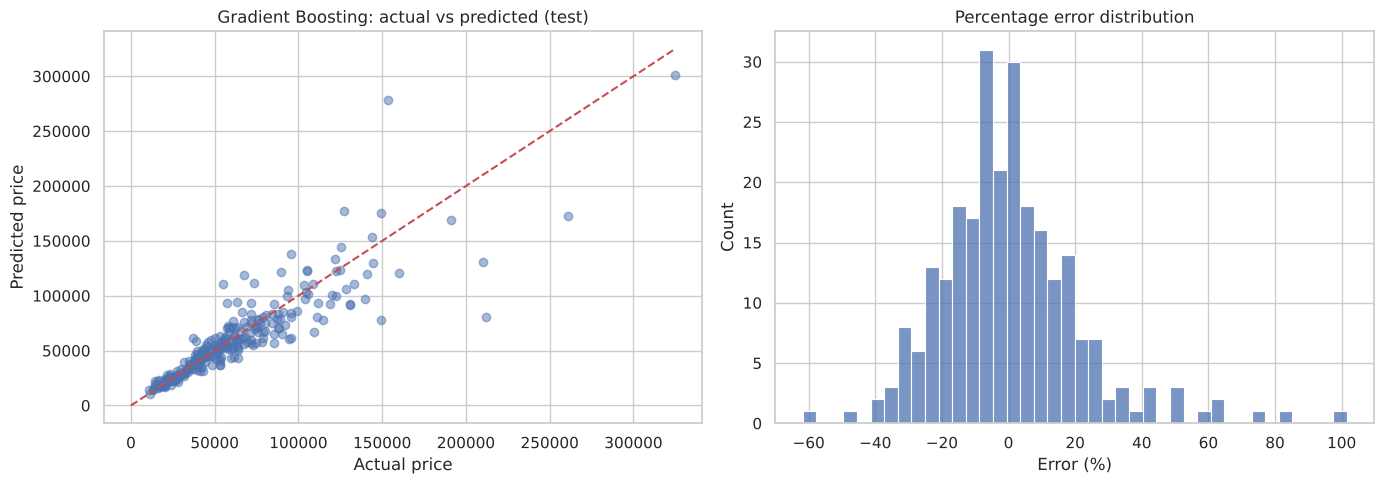

In [12]:
pred = best_model.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, pred, alpha=.5); lim = [0, max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price"); ax[0].set_title(f"{cv_best}: actual vs predicted (test)")
sns.histplot((pred - y_test) / y_test * 100, bins=40, ax=ax[1]); ax[1].set_xlabel("Error (%)"); ax[1].set_title("Percentage error distribution")
plt.tight_layout(); plt.savefig("assets/eval.png", dpi=110); plt.show()

### Error analysis

In [13]:
err = pd.DataFrame({"Company": X_test.Company, "TypeName": X_test.TypeName, "actual": y_test, "pred": pred})
err["abs_err"] = (err.pred - err.actual).abs(); err["pct_err"] = err.abs_err / err.actual * 100
print("Median % error:", round(err.pct_err.median(), 1), "| within 20%:", round((err.pct_err <= 20).mean() * 100, 1), "%")
RESULTS["median_pct_err"] = round(float(err.pct_err.median()), 1)
RESULTS["within_20pct"] = round(float((err.pct_err <= 20).mean() * 100), 1)

err["price_band"] = pd.qcut(err.actual, 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 most expensive"])
band = err.groupby("price_band").agg(n=("actual", "size"), MAE=("abs_err", "mean"), median_pct_err=("pct_err", "median")).round(1)
display(band); RESULTS["error_by_band"] = band.to_dict(orient="index")
bytype = err.groupby("TypeName").agg(n=("actual", "size"), MAE=("abs_err", "mean"), median_pct_err=("pct_err", "median")).round(1)
display(bytype)
print("Five worst predictions:")
display(err.sort_values("abs_err", ascending=False).head(5).round(0))

Median % error: 11.5 | within 20%: 73.3 %


,n,MAE,median_pct_err
price_band,,,
Q1 cheapest,64,3001.9,9.3
Q2,64,5386.2,8.3
Q3,63,11002.4,11.9
Q4 most expensive,64,24595.3,16.4


,n,MAE,median_pct_err
TypeName,,,
2 in 1 Convertible,18,10581.4,16.8
Gaming,48,20971.0,17.1
Netbook,4,9663.9,29.4
Notebook,145,5803.6,8.7
Ultrabook,31,13492.8,10.5
Workstation,9,34283.3,16.2


Five worst predictions:


,Company,TypeName,actual,pred,abs_err,pct_err,price_band
1066,Asus,Gaming,211788.0,80810.0,130978.0,62.0,Q4 most expensive
297,Dell,Workstation,153705.0,278472.0,124767.0,81.0,Q4 most expensive
610,Lenovo,Notebook,261019.0,172725.0,88293.0,34.0,Q4 most expensive
1136,HP,Workstation,210424.0,131157.0,79267.0,38.0,Q4 most expensive
650,Asus,Gaming,149131.0,78060.0,71071.0,48.0,Q4 most expensive


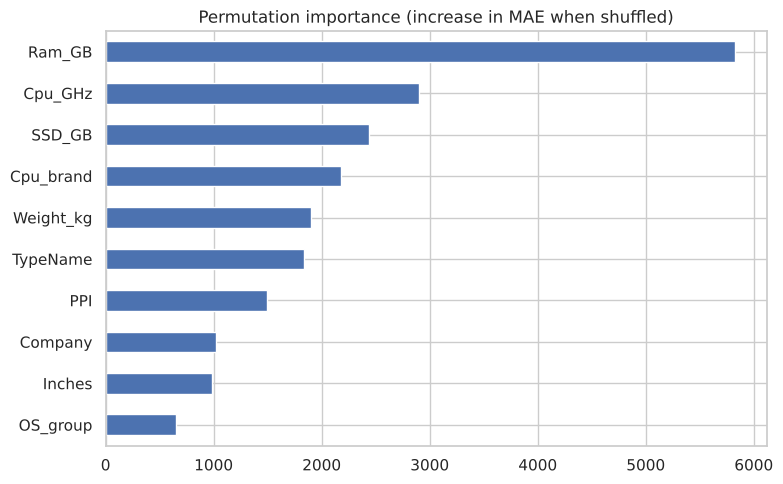

Ram_GB       5827.0
Cpu_GHz      2898.0
SSD_GB       2439.0
Cpu_brand    2179.0
Weight_kg    1903.0
TypeName     1833.0
PPI          1496.0
Company      1019.0
dtype: float64


In [14]:
imp = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                             scoring="neg_mean_absolute_error", n_jobs=-1)
imp_df = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp_df.head(10).iloc[::-1].plot.barh(figsize=(8, 5), title="Permutation importance (increase in MAE when shuffled)")
plt.tight_layout(); plt.savefig("assets/importance.png", dpi=110); plt.show()
print(imp_df.head(8).round(0))
RESULTS["top_features"] = [str(i) for i in imp_df.head(5).index]

## 8 · Learned model vs rule-based hardware ranking
A rule-based PC ranking assigns points to RAM, storage, CPU tier and GPU. Does a learned model rank machines by price better than hand-picked weights?

In [15]:
rule = rule_based_score(X_test)
rho_rule = spearmanr(rule, y_test).correlation
rho_model = spearmanr(pred, y_test).correlation
print(f"Spearman with real price -> rule-based score: {rho_rule:.3f} | learned model: {rho_model:.3f}")
RESULTS["spearman_rule"] = round(float(rho_rule), 3); RESULTS["spearman_model"] = round(float(rho_model), 3)

Spearman with real price -> rule-based score: 0.734 | learned model: 0.938


## 9 · Hardware tiers (K-Means + PCA)
We cluster on **specs only** (not price), fitting on the training set. Then we check whether the discovered tiers line up with price.

{3: 0.24, 4: 0.24, 5: 0.249, 6: 0.264}


,n,median_price,RAM,GHz,SSD,HDD,PPI,kg,dedicated_GPU
Tier,,,,,,,,,
Tier 1 · Entry,278,30076.56,4.0,2.3,0.0,500.0,111.94,2.04,0.00
Tier 2 · Mainstream,295,44275.68,8.0,2.5,128.0,1000.0,141.21,2.20,1.00
Tier 3 · Slim Premium,320,74272.05,8.0,2.5,256.0,0.0,165.63,1.36,0.07
Tier 4 · High-Performance,126,102004.56,16.0,2.8,256.0,1000.0,141.21,2.72,1.00


Test-set median price per tier (tiers use specs only):
Tier
Tier 1 · Entry                31382.0
Tier 2 · Mainstream           47286.0
Tier 3 · Slim Premium         65082.0
Tier 4 · High-Performance    116923.0
Name: Price, dtype: float64


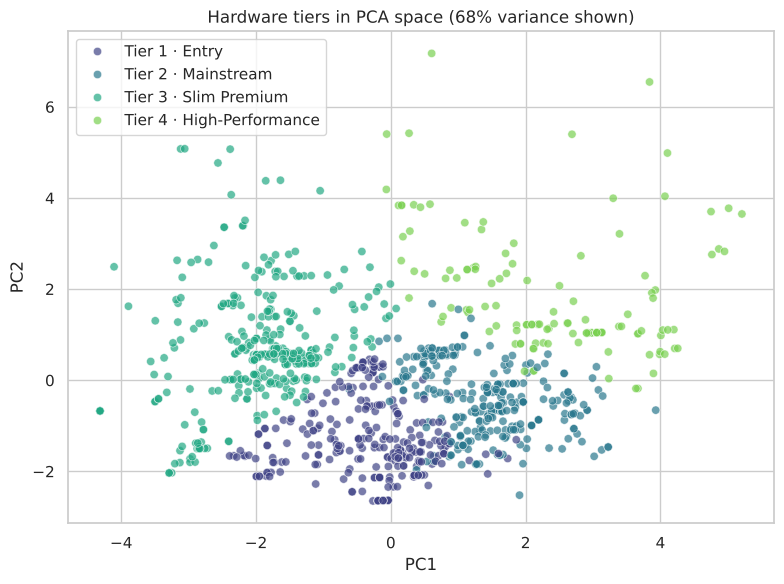

In [16]:
tier_cols = ["Ram_GB", "Cpu_GHz", "SSD_GB", "HDD_GB", "PPI", "Weight_kg", "Inches", "Dedicated_GPU"]
scaler_t = StandardScaler().fit(X_train[tier_cols].fillna(X_train[tier_cols].median()))
Z_train = scaler_t.transform(X_train[tier_cols].fillna(X_train[tier_cols].median()))

sil = {}
for k in range(3, 7):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_train)
    sil[k] = silhouette_score(Z_train, km_k.labels_)
print({k: round(v, 3) for k, v in sil.items()})
K = 4  # we want an interpretable 4-level ladder (silhouette scores above are shown for transparency)
RESULTS["silhouette"] = {int(k): round(float(v), 3) for k, v in sil.items()}; RESULTS["k_tiers"] = K
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z_train)

# Order clusters by the median TRAIN price so Tier 1 = cheapest
order = pd.Series(y_train.values).groupby(km.labels_).median().sort_values().index.tolist()
rank_of = {c: i for i, c in enumerate(order)}
# Names were chosen AFTER reading the cluster profiles below (ordered by median price)
names = ["Tier 1 · Entry", "Tier 2 · Mainstream", "Tier 3 · Slim Premium", "Tier 4 · High-Performance"]
tier_names = {rank_of[c]: names[rank_of[c]] for c in range(K)}

def assign_tier(X):
    Z = scaler_t.transform(X[tier_cols].fillna(X_train[tier_cols].median()))
    return pd.Series([rank_of[c] for c in km.predict(Z)], index=X.index).map(tier_names)

tr = X_train.assign(Tier=assign_tier(X_train), Price=y_train)
profile = tr.groupby("Tier").agg(n=("Price", "size"), median_price=("Price", "median"), RAM=("Ram_GB", "median"),
                                 GHz=("Cpu_GHz", "median"), SSD=("SSD_GB", "median"), HDD=("HDD_GB", "median"),
                                 PPI=("PPI", "median"), kg=("Weight_kg", "median"), dedicated_GPU=("Dedicated_GPU", "mean")).round(2)
display(profile); RESULTS["tier_profile"] = profile.to_dict(orient="index")

te = X_test.assign(Tier=assign_tier(X_test), Price=y_test)
print("Test-set median price per tier (tiers use specs only):")
print(te.groupby("Tier").Price.median().round(0))

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z_train)
P = pca.transform(Z_train)
plt.figure(figsize=(8, 6)); sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=tr.Tier.values, hue_order=names, palette="viridis", alpha=.7)
plt.title(f"Hardware tiers in PCA space ({pca.explained_variance_ratio_.sum()*100:.0f}% variance shown)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.tight_layout(); plt.savefig("assets/tiers_pca.png", dpi=110); plt.show()
RESULTS["pca_var_2d"] = round(float(pca.explained_variance_ratio_.sum()), 3)

## 10 · "Good deal" thresholds for the app
To judge a quoted price we need to know how far *real* prices normally sit from the model's fair price. We measure this with **out-of-fold predictions on the training set** (no test data): the 25% most under-priced laptops are "good deals", the 25% most over-priced are "overpriced".

In [17]:
oof = cross_val_predict(final[cv_best], X_train, y_train, cv=cv)
log_ratio = np.log(y_train.values / oof)
lo, hi = np.quantile(log_ratio, [0.25, 0.75])
print(f"Good deal if quoted price < {np.exp(lo):.2f} x fair price | overpriced if > {np.exp(hi):.2f} x fair price")
RESULTS["deal_low_ratio"] = round(float(np.exp(lo)), 3); RESULTS["deal_high_ratio"] = round(float(np.exp(hi)), 3)

Good deal if quoted price < 0.89 x fair price | overpriced if > 1.12 x fair price


## 11 · Save artifacts for the web app
The final pipeline is **refit on train + test** (all data) so the deployed model uses every laptop. The numbers reported above come from the train-only model evaluated on the held-out test set.

In [18]:
from sklearn.base import clone
deploy_model = clone(final[cv_best]).fit(X_all, y_all)
joblib.dump(deploy_model, "models/price_pipeline.joblib", compress=3)

# tier model artifacts (re-fit on all data with the same settings)
fill = X_all[tier_cols].median()
sc_all = StandardScaler().fit(X_all[tier_cols].fillna(fill))
km_all = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(sc_all.transform(X_all[tier_cols].fillna(fill)))
order_all = pd.Series(y_all.values).groupby(km_all.labels_).median().sort_values().index.tolist()
joblib.dump({"scaler": sc_all, "kmeans": km_all, "fill": fill.to_dict(), "cols": tier_cols,
             "rank_of": {int(c): i for i, c in enumerate(order_all)}, "names": names},
            "models/tier_model.joblib", compress=3)

resolutions = (raw["ScreenResolution"].str.extract(r"(\d{3,4}x\d{3,4})")[0].value_counts().index.tolist())
meta = {
    "choices": {c: sorted(X_all[c].unique().tolist()) for c in CAT_COLS},
    "ram": sorted(X_all.Ram_GB.unique().tolist()), "inches": sorted(X_all.Inches.unique().tolist()),
    "resolutions": resolutions,
    "price_min": float(y_all.min()), "price_max": float(y_all.max()), "price_median": float(y_all.median()),
    "deal_low_ratio": RESULTS["deal_low_ratio"], "deal_high_ratio": RESULTS["deal_high_ratio"],
    "best_model": cv_best, "test_mae": RESULTS["test"][cv_best]["MAE"], "test_r2": RESULTS["test"][cv_best]["R2"],
    "median_pct_err": RESULTS["median_pct_err"],
}
json.dump(meta, open("models/meta.json", "w"), indent=2)
json.dump(RESULTS, open("results.json", "w"), indent=2, default=str)
print("Saved: models/price_pipeline.joblib, models/tier_model.joblib, models/meta.json, results.json")

Saved: models/price_pipeline.joblib, models/tier_model.joblib, models/meta.json, results.json


## 12 · Business insight & limitations
*(Numbers quoted here are printed above by this notebook; see `results.json`.)*

**What the results mean.** A tuned ensemble model predicts a laptop's fair price far better than the "always predict the average" baseline, and it ranks machines by price better than a hand-written points system built from the same specs. A manager can use the app to (1) sanity-check a vendor quote, (2) budget new purchases from the spec sheet, and (3) see which hardware tier each machine belongs to when deciding what to upgrade or retire.

**What the company should do next.**
- Use the "fair price" as a *negotiation reference*, and only trust it within the typical error band shown in the app.
- Replace the hand-written ranking in the asset system with the model score plus tier, and re-train when new purchase data arrives.
- Collect the organisation's own purchase prices and machine ages so the model reflects local prices.

**Limitations.**
- Only ~1,270 unique laptops, from one snapshot in time: **no date feature**, so prices drift as hardware ages and the model will go stale.
- The data has list prices of *new* retail laptops; it says nothing about used machines, depreciation or condition.
- Specs are parsed from text, so rare CPUs/GPUs are grouped coarsely (family, not exact model), and very expensive machines are predicted less accurately (see the error-by-price-band table).
- Tiers are based on specs only; they describe hardware class, not whether a machine is *healthy* or *failing*.